# CS-363M Final Project

Wildlife strike damage prediction for the class competition. This notebook loads the FAA strike data, engineers features, tunes the probability threshold for balanced accuracy, and writes `submission.csv`.

In [43]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: C:\Users\deanc\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [44]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

### Process Files

In [45]:
TRAIN_PATH = Path("train.csv/train.csv")
TEST_PATH = Path("test.csv/test.csv")
SAMPLE_PATH = Path("sample_submission.csv/sample_submission.csv")
SUBMISSION_PATH = Path("submission.csv")
RANDOM_STATE = 42
TARGET = "INDICATED_DAMAGE"
ID_COL = "INDEX_NR"

train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)

print(train.shape)
print(test.shape)
train.head()

(307178, 55)
(34131, 54)


,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NUM_SEEN,NUM_STRUCK,SIZE,ENROUTE_STATE,COMMENTS,SOURCE,PERSON,LUPDATE,TRANSFER,INDICATED_DAMAGE
0,1410120,12/13/93,12,1993,NaN,Day,TJSJ,LUIS MUNOZ MARIN INTL,18.43942,-66.00183,...,10-Feb,10-Feb,Small,NaN,NaN,FAA Form 5200-7,Pilot,4/3/23,0,0
1,709688,2/1/10,2,2010,5:00,Night,WMKK,KUALA LUMPUR INTL,2.745578,101.709917,...,NaN,1,Medium,NaN,2010-5-18-53374 /Legacy Record 300758/,FAA Form 5200-7-E,Air Transport Operations,6/9/10,0,0
2,730841,5/9/12,5,2012,2:00,Night,KSDF,MUHAMMAD ALI INTERNATIONAL,38.17439,-85.736,...,NaN,1,Large,NaN,UPS EVENT REPT 36216 (4/22/13 UPDATED COST) /L...,Air Transport Report,Air Transport Operations,4/22/13,0,1
3,654676,10/8/02,10,2002,NaN,NaN,KLAX,LOS ANGELES INTL,33.94254,-118.40807,...,NaN,10-Feb,Medium,NaN,2002-10-8-111929 /Legacy Record 216397/,FAA Form 5200-7-E,Carcass Found,1/9/03,0,0
4,629708,2/3/97,2,1997,NaN,Dawn,PHLI,LIHUE ARPT,21.97598,-159.33896,...,1,1,Medium,NaN,SOURCE 5200-7 & PACIR /Legacy Record 121531/,Multiple,NaN,3/1/07,0,0


# Data Exploration

Train dataset shape: (307178, 55)
Test dataset shape: (34131, 54)

Missing values in train (top 10):
BIRD_BAND_NUMBER    306465
ENG_4_POS           303909
ENROUTE_STATE       301832
PRECIPITATION       295966
ENG_3_POS           294822
LOCATION            267960
SPEED               212076
NUM_SEEN            208546
SKY                 162825
FLT                 161435
dtype: int64


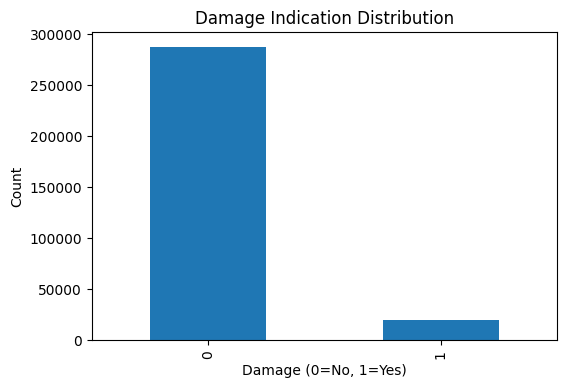

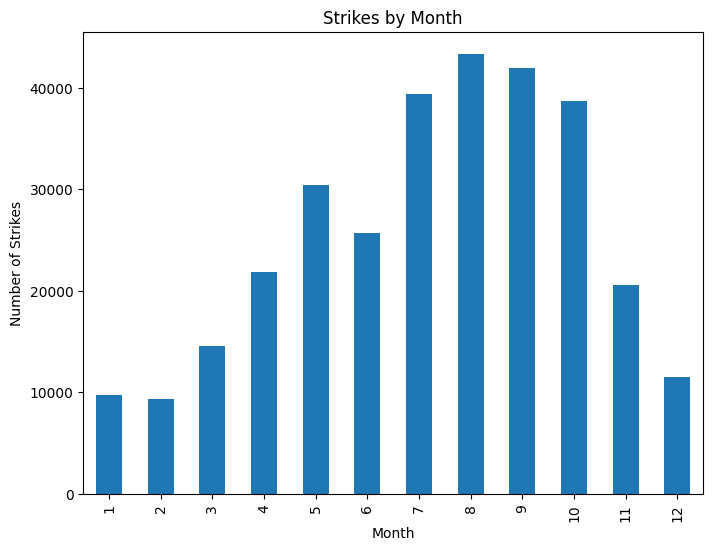

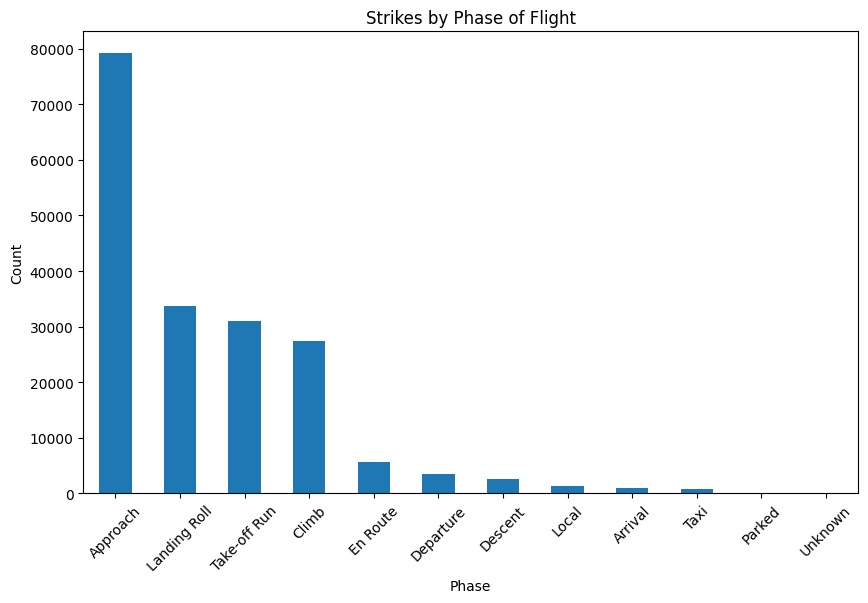

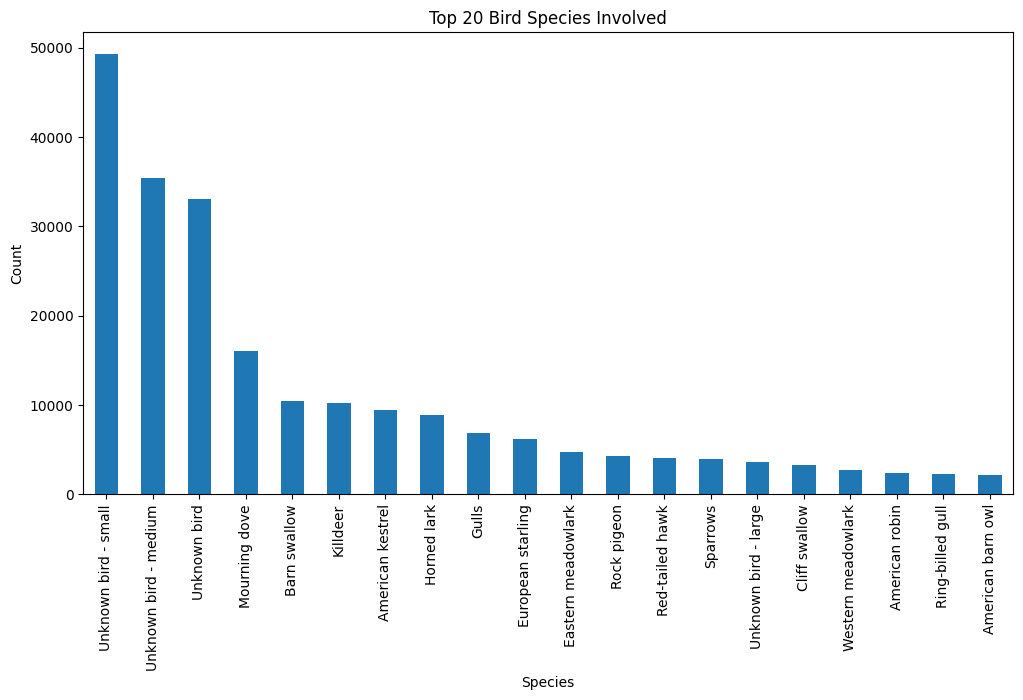

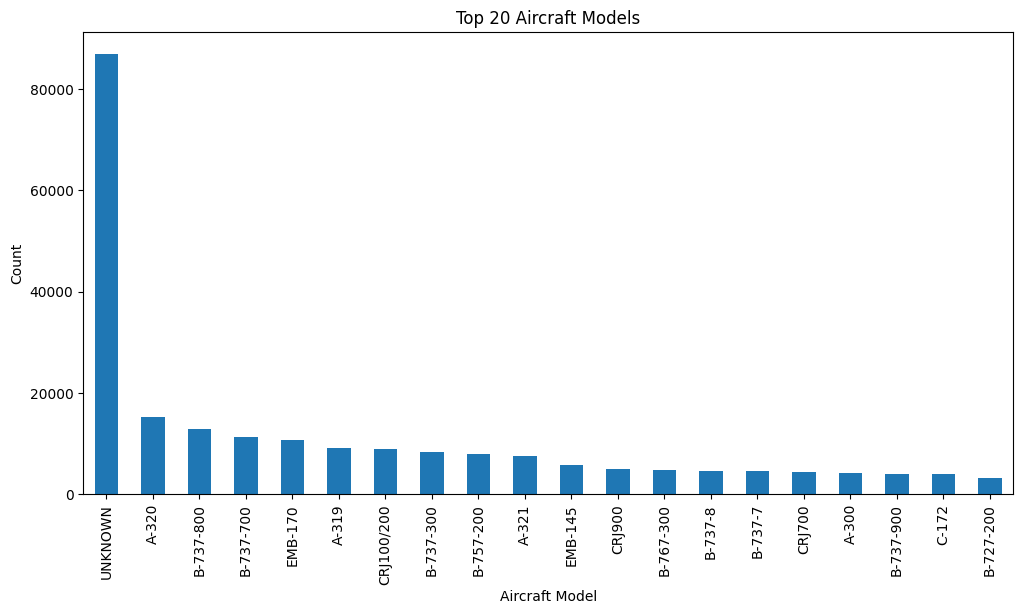

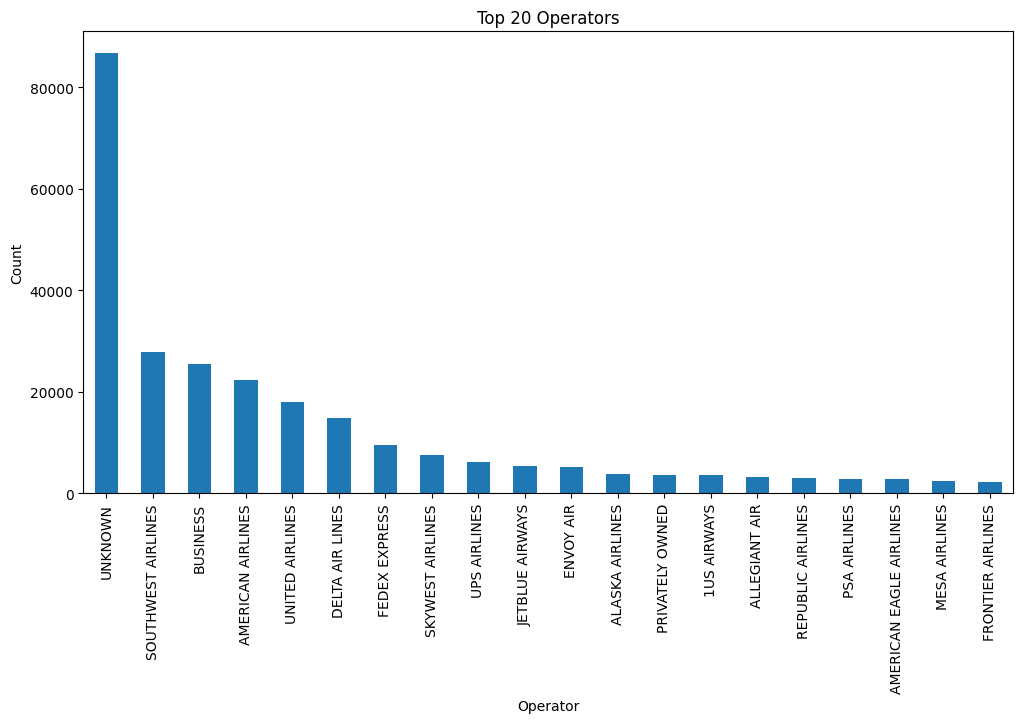

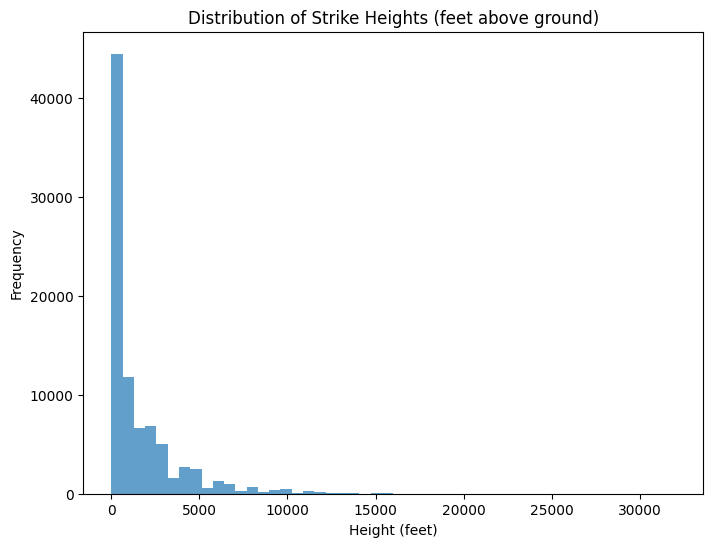

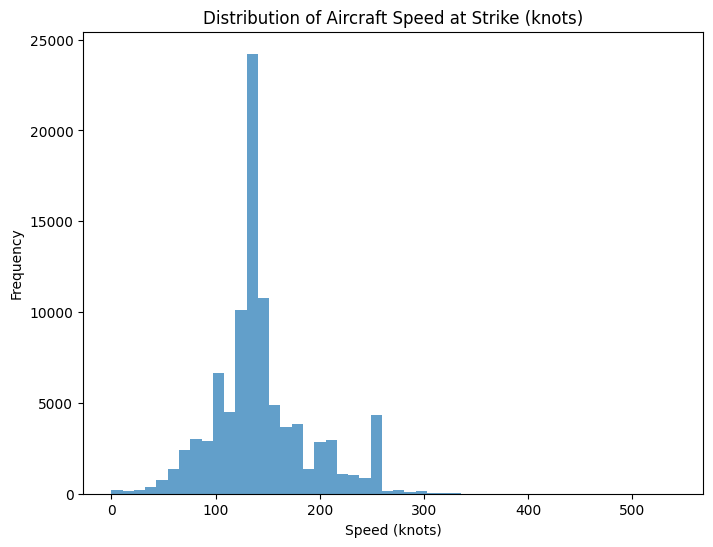

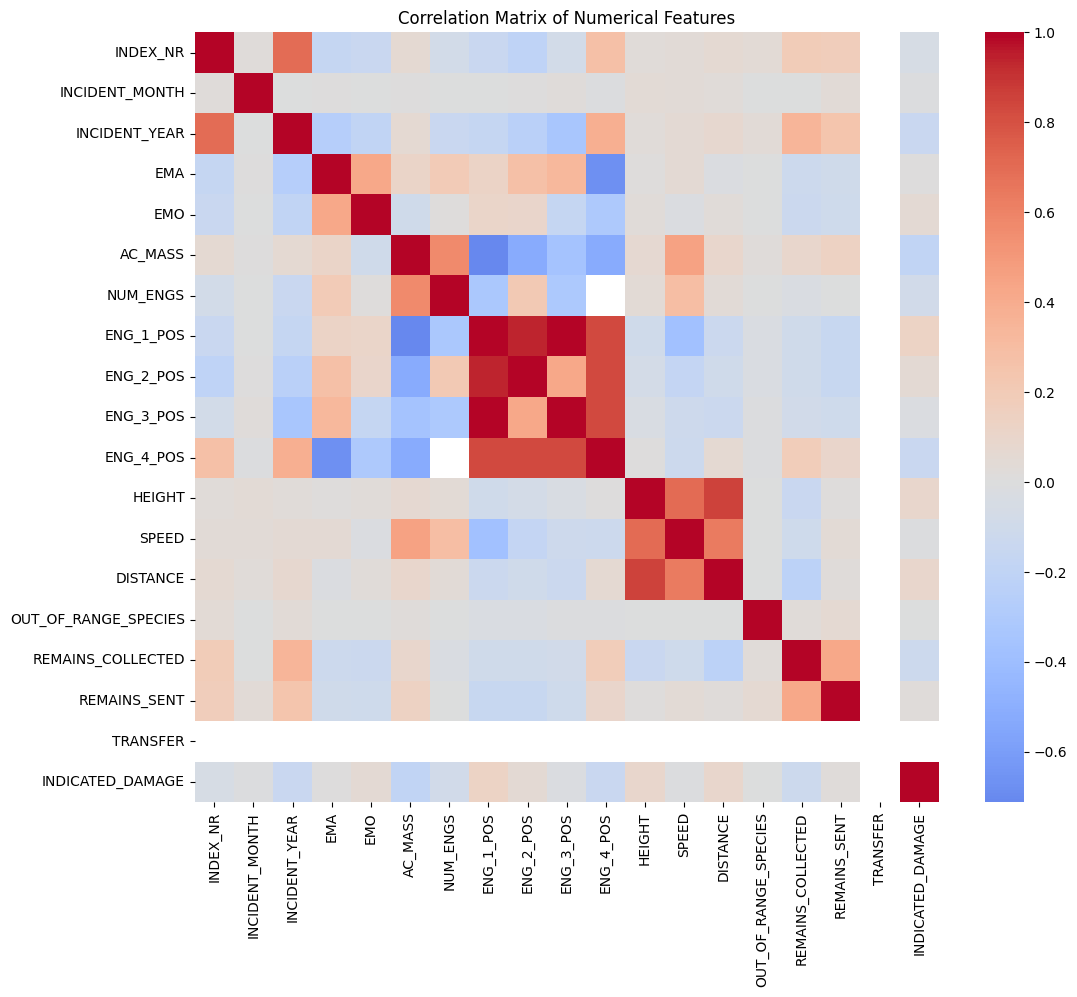

In [46]:
# Data Exploration and Visualization!!!!

# Basic dataset info
print("Train dataset shape:", train.shape)
print("Test dataset shape:", test.shape)
# Missing values
# we have lots of missing values in columns, this is importnant!
missing_train = train.isnull().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)
print("\nMissing values in train (top 10):")
print(missing_train.head(10))


# Target variable distribution, this is important to understand the class balance!!!
plt.figure(figsize=(6,4))
train[TARGET].value_counts().plot(kind='bar')
plt.title('Damage Indication Distribution')
plt.xlabel('Damage (0=No, 1=Yes)')
plt.ylabel('Count')
plt.show()


# Specific feature distributions that are useful in data exploration
# Strikes by month, shows different birds in seasons
if 'INCIDENT_MONTH' in train.columns:
    plt.figure(figsize=(8,6))
    train['INCIDENT_MONTH'].value_counts().sort_index().plot(kind='bar')
    plt.title('Strikes by Month')
    plt.xlabel('Month')
    plt.ylabel('Number of Strikes')
    plt.show()
# Phase of flight, shows different risks at different phases of the flight
if 'PHASE_OF_FLIGHT' in train.columns:
    plt.figure(figsize=(10,6))
    train['PHASE_OF_FLIGHT'].value_counts().plot(kind='bar')
    plt.title('Strikes by Phase of Flight')
    plt.xlabel('Phase')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()
# Top species, shows bird species in accidents
if 'SPECIES' in train.columns:
    plt.figure(figsize=(12,6))
    train['SPECIES'].value_counts().head(20).plot(kind='bar')
    plt.title('Top 20 Bird Species Involved')
    plt.xlabel('Species')
    plt.ylabel('Count')
    plt.xticks(rotation=90)
    plt.show()
# Aircraft types, shows diff models, BUT mostly for UNKNOWN data! data quality is possibly really bad (bruh!)
if 'AIRCRAFT' in train.columns:
    plt.figure(figsize=(12,6))
    train['AIRCRAFT'].value_counts().head(20).plot(kind='bar')
    plt.title('Top 20 Aircraft Models')
    plt.xlabel('Aircraft Model')
    plt.ylabel('Count')
    plt.xticks(rotation=90)
    plt.show()
# Operators, once again, data quality is maybe bad :(
if 'OPERATOR' in train.columns:
    plt.figure(figsize=(12,6))
    train['OPERATOR'].value_counts().head(20).plot(kind='bar')
    plt.title('Top 20 Operators')
    plt.xlabel('Operator')
    plt.ylabel('Count')
    plt.xticks(rotation=90)
    plt.show()
# Height distribution, shows average height for strikes!
if 'HEIGHT' in train.columns:
    height_data = train[train['HEIGHT'] > 0]['HEIGHT']
    if not height_data.empty:
        plt.figure(figsize=(8,6))
        plt.hist(height_data, bins=50, alpha=0.7)
        plt.title('Distribution of Strike Heights (feet above ground)')
        plt.xlabel('Height (feet)')
        plt.ylabel('Frequency')
        plt.show()
# Speed distribution, shows average speed for strikes
if 'SPEED' in train.columns:
    speed_data = train['SPEED'].dropna()
    if not speed_data.empty:
        plt.figure(figsize=(8,6))
        plt.hist(speed_data, bins=50, alpha=0.7)
        plt.title('Distribution of Aircraft Speed at Strike (knots)')
        plt.xlabel('Speed (knots)')
        plt.ylabel('Frequency')
        plt.show()


# Big correlation heatmap to see any visual correlations for numeraical features
numerical_cols = train.select_dtypes(include=[np.number]).columns
if len(numerical_cols) > 1:
    corr_matrix = train[numerical_cols].corr()
    plt.figure(figsize=(12,10))
    sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
    plt.title('Correlation Matrix of Numerical Features')
    plt.show()

# Data Preprocessing (includes both Cleaning and Feature Engineering)

In [47]:


# Dropped these features because they will either cause overfitting (Identifiers),
# they are unstructured data (text), or they are primarily NaN
DROP_AFTER_FEATURES = [
    "INCIDENT_DATE", #redundant with month/year
    "LUPDATE", # can cause overfitting because recent update does not always equal damage
    "TIME", # redundant with time of day/ too specific
    "REMARKS", # text
    "COMMENTS", # text
    "LOCATION", # overfitting
    "REG", # ID overfitting
    "FLT", # irrelevant to birdstrikes
    "BIRD_BAND_NUMBER", # very rare, typically NaN
]


# used a filter to see if the text features have these words. Used to create new feature
# "has_damage_word"
DAMAGE_KEYWORDS = re.compile(
    r"damage|damaged|dent|dented|crack|cracked|hole|bent|broke|broken|"
    r"shatter|shattered|replace|replaced|repair|repaired|destroy",
    re.IGNORECASE,
)



def parse_time_to_minutes(value):
    if pd.isna(value):
        return np.nan
    match = re.match(r"^\s*(\d{1,2}):(\d{2})\s*$", str(value))
    if not match:
        return np.nan
    hour, minute = int(match.group(1)), int(match.group(2))
    if hour > 23 or minute > 59:
        return np.nan
    return hour * 60 + minute


def count_bucket_midpoint(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if not text:
        return np.nan
    normalized = text.lower()
    if normalized in {"1", "1.0"}:
        return 1.0
    if normalized in {"10-feb", "2-10", "02-oct"}:
        return 6.0
    if normalized == "11-100":
        return 55.5
    if normalized == "more than 100":
        return 150.0
    try:
        return float(text)
    except ValueError:
        return np.nan


def add_features(df):
    engineered = df.copy()

    incident_date = pd.to_datetime(engineered.get("INCIDENT_DATE"), format="%m/%d/%y", errors="coerce")
    engineered["INCIDENT_DAYOFWEEK"] = incident_date.dt.dayofweek
    engineered["INCIDENT_DAYOFYEAR"] = incident_date.dt.dayofyear
    engineered["INCIDENT_QUARTER"] = incident_date.dt.quarter
    engineered["INCIDENT_IS_WEEKEND"] = incident_date.dt.dayofweek.isin([5, 6]).astype("int8")

    last_update = pd.to_datetime(engineered.get("LUPDATE"), format="%m/%d/%y", errors="coerce")
    engineered["LUPDATE_YEAR"] = last_update.dt.year
    engineered["LUPDATE_MONTH"] = last_update.dt.month
    engineered["DAYS_TO_UPDATE"] = (last_update - incident_date).dt.days

    time_minutes = engineered.get("TIME", pd.Series(index=engineered.index, dtype="object")).map(parse_time_to_minutes)
    engineered["TIME_MINUTES"] = time_minutes
    engineered["TIME_HOUR"] = np.floor(time_minutes / 60)
    engineered["TIME_KNOWN"] = time_minutes.notna().astype("int8")

    for col in ["NUM_SEEN", "NUM_STRUCK"]:
        if col in engineered:
            engineered[f"{col}_MIDPOINT"] = engineered[col].map(count_bucket_midpoint)

    if "SIZE" in engineered:
        size_map = {"Small": 1, "Medium": 2, "Large": 3}
        engineered["SIZE_ORDINAL"] = engineered["SIZE"].map(size_map)

    for col in df.columns:
        if col not in {TARGET, ID_COL}:
            engineered[f"{col}_MISSING"] = engineered[col].isna().astype("int8")

    for col in ["REMARKS", "COMMENTS", "LOCATION"]:
        if col in engineered:
            text = engineered[col].fillna("").astype(str)
            engineered[f"{col}_LEN"] = text.str.len()
            engineered[f"{col}_WORDS"] = text.str.split().str.len()
            engineered[f"{col}_HAS_DAMAGE_WORD"] = text.str.contains(DAMAGE_KEYWORDS).astype("int8")

    for col in engineered.select_dtypes(include="object").columns:
        engineered[col] = engineered[col].fillna("MISSING").astype(str).str.strip().str.upper()
        engineered.loc[engineered[col].eq(""), col] = "MISSING"

    return engineered.drop(columns=[col for col in DROP_AFTER_FEATURES if col in engineered.columns], errors="ignore")


def make_preprocessor(features):
    numeric_cols = features.select_dtypes(exclude="object").columns.tolist()
    categorical_cols = features.select_dtypes(include="object").columns.tolist()

    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), numeric_cols),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
                        (
                            "encoder",
                            OrdinalEncoder(
                                handle_unknown="use_encoded_value",
                                unknown_value=-1,
                                encoded_missing_value=-1,
                                min_frequency=10,
                                max_categories=512,
                                dtype=np.float32,
                            ),
                        ),
                    ]
                ),
                categorical_cols,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )




## Preprocessing Driver

In [48]:
y = train[TARGET].astype(int)
X = add_features(train.drop(columns=[TARGET]))
X_test = add_features(test)
test_ids = test[ID_COL]

X = X.drop(columns=[ID_COL], errors="ignore")
X_test = X_test.drop(columns=[ID_COL], errors="ignore")
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = make_preprocessor(X_train)
X_train_prepared = preprocessor.fit_transform(X_train)
X_valid_prepared = preprocessor.transform(X_valid)


# Training the Model

In [49]:
# train 2 separate models to use for ensemble voting method
# train 2 models to make an ensemble, then we get the best threshold 
MODEL_CONFIGS = [
    {
        "loss": "log_loss",
        "learning_rate": 0.04, # lower rate to reduce overfitting
        "max_iter": 600, # more iterations to allow better convergence
        "max_leaf_nodes": 31, # smaller trees to reduce overfitting
        "l2_regularization": 0.05, # stronger regularization to combat overfitting
        "early_stopping": True, # enable early stopping to prevent overfitting
        "validation_fraction": 0.12, # use a portion of training data for early stopping validation
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
    },
    {
        "loss": "log_loss", 
        "learning_rate": 0.06, # slightly higher learning rate for a different convergence path
        "max_iter": 450, # fewer iterations for a different convergence path and reduce overfitting
        "max_leaf_nodes": 127, # larger trees to alolw for a different convergence path
        "min_samples_leaf": 30, # require more samples per leaf to reduce overfitting
        "l2_regularization": 0.01, # moderate regularization to balance bias and variance
        "early_stopping": True,
        "validation_fraction": 0.12,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
    },
]

# Create and train the ensemble models based on the configurations defined above
def make_models():
    return [HistGradientBoostingClassifier(**config) for config in MODEL_CONFIGS]

# Returns a list of the ensemble models
def ensemble_probabilities(models, features):
    probabilities = [model.predict_proba(features)[:, 1] for model in models]
    return np.mean(probabilities, axis=0)

# Finds the best threshold for converting probabilities to binary predictions based on balanced accuracy
def best_threshold(y_true, probabilities):
    candidates = np.unique(np.r_[np.linspace(0.03, 0.97, 189), np.quantile(probabilities, np.linspace(0.01, 0.99, 99))])
    scores = [
        (balanced_accuracy_score(y_true, probabilities >= threshold), threshold) # calculate balanced accuracy for each threshold
        for threshold in candidates
    ]
    score, threshold = max(scores, key=lambda item: item[0]) # get the best score and corresponding threshold
    return float(threshold), float(score)

In [ ]:
**Ensemble Method**: We used an ensemble approach with two HistGraiedntBoostingClassifier 
models that have different settings to make predictions more reliable and reduce overfitting.

**Model Configurations**: 
  - One model has a slow learning rate (0.04), small trees (31 leaves), and strong regularization 
(L2=0.05) for steady learinng.
  - The other has a faster learning rate (0.06), bigger trees (127 leaves), and lighter regularization 
(L2=0.01) to catch different patterns.

**Handling Imbalanced Data**: Both models give moer weight to rare damage cases, use early 
stopping with 12% validation data to avoid overfitting, and have a fixed random seed for consistent results.

**Training Process**: We split the data 80-20 for training and validation, fit both models, 
then average their probability predictions.

**Threshold Tuning**: Instead of the default 0.5 cutoff, we tested many threhsolds to find 
the best one for balanced accuracy on validation, treating both damage and no-damage cases fairly.

**Why It Works Better**: This ensemble with a tuned threshold outperforms a single model by 
combining different strengths and optimizing for the competition metric.

SyntaxError: invalid syntax (271074152.py, line 1)

## Training Driver

In [50]:
# Run the methods we made above to train teh models

# Train the ensemble models on the prepared training data
models = make_models()
for model in models:
    model.fit(X_train_prepared, y_train)

# Evaluate the ensemble on the validation set using 0.5 threshold, then find the best threshold!
valid_probabilities = ensemble_probabilities(models, X_valid_prepared)
default_score = balanced_accuracy_score(y_valid, valid_probabilities >= 0.5)
threshold, tuned_score = best_threshold(y_valid, valid_probabilities)
valid_predictions = (valid_probabilities >= threshold).astype(int)

# Print out the results and evaluation metrics for the validation set
print(f"Training rows: {len(X_train):,} | validation rows: {len(X_valid):,}")
print(f"Target damage rate: {y.mean():.4%}")
print(f"Balanced accuracy at 0.50 threshold: {default_score:.5f}")
print(f"Best validation threshold: {threshold:.5f}")
print(f"Best validation balanced accuracy: {tuned_score:.5f}")
print(classification_report(y_valid, valid_predictions, digits=4))

Training rows: 245,742 | validation rows: 61,436
Target damage rate: 6.3569%
Balanced accuracy at 0.50 threshold: 0.86386
Best validation threshold: 0.46000
Best validation balanced accuracy: 0.86484
              precision    recall  f1-score   support

           0     0.9883    0.8838    0.9332     57531
           1     0.3308    0.8458    0.4756      3905

    accuracy                         0.8814     61436
   macro avg     0.6595    0.8648    0.7044     61436
weighted avg     0.9465    0.8814    0.9041     61436



In [51]:
# Train final models on full training data
final_preprocessor = make_preprocessor(X)
X_prepared = final_preprocessor.fit_transform(X)
X_test_prepared = final_preprocessor.transform(X_test)
# Train final models on full training data, this is to get the best performance!
final_models = make_models()
for model in final_models:
    model.fit(X_prepared, y)

# Predict on test data using tuned threshold
# this is where we get the final predictions for the final submission
test_probabilities = ensemble_probabilities(final_models, X_test_prepared)
test_predictions = (test_probabilities >= threshold).astype(int)

# Create and write teh submission file (we submit this!)
submission = pd.read_csv(SAMPLE_PATH)
submission[ID_COL] = test_ids.values
submission[TARGET] = test_predictions
submission.to_csv(SUBMISSION_PATH, index=False)

# Final thoughts, and the submission head(debugging the submission file)
print(f"Final Accuracy: {tuned_score:.5f} ")
submission.head()

Final Accuracy: 0.86484 


,INDEX_NR,INDICATED_DAMAGE
0,9000000,0
1,9000001,0
2,9000002,0
3,9000003,0
4,9000004,1
